# 04 — Anomaly Detection & Cluster Analysis

**Goal:** Detect anomalous windows using z-scores, build binary activation profiles, discover recurring patterns via hierarchical clustering, and statistically analyze each cluster.

**Depends on:** NB02 (windowed feature datasets)

In [1]:
import sys, os, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import f1_score
import joblib
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('..'))
ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')

# Load supervised datasets + RF model
train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))
train_sup['window_end'] = pd.to_datetime(train_sup['window_end'])
test_sup['window_end'] = pd.to_datetime(test_sup['window_end'])

saved = joblib.load(os.path.join(OUT_DIR, 'supervised', 'rf_model.joblib'))
rf_model = saved['model']
RF_THR = saved['threshold']

feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]

# Combine train+test
train_sup['split'] = 'train'
test_sup['split'] = 'test'
all_sup = pd.concat([train_sup, test_sup], ignore_index=True).sort_values('window_end').reset_index(drop=True)
del train_sup, test_sup; gc.collect()

# Subsystem mapping
def get_subsystem(name):
    name_upper = name.upper()
    if 'DAYS_SINCE' in name_upper:
        return 'Asset'
    if 'MAIN_RESERVOIR' in name_upper or 'COMPRESSOR' in name_upper:
        return 'APU'
    if 'LOAD_PRESSURE' in name_upper or 'LOAD_SIGNAL' in name_upper:
        return 'Leveling'
    if 'ENERGY_BRAKING' in name_upper:
        return 'Traction'
    if 'SPEED' in name_upper or 'TEMPERATURE' in name_upper:
        return 'Context'
    return 'Brake'

feat_subsystem = {f: get_subsystem(f) for f in feature_cols}

SPLIT_DATE = pd.Timestamp('2025-02-12')
print(f'Total windows: {len(all_sup):,} | Features: {len(feature_cols)}')
print(f'Failure windows: {all_sup["label"].sum()} ({100*all_sup["label"].mean():.2f}%)')

Total windows: 64,522 | Features: 340
Failure windows: 1202 (1.86%)


## 1. Identify Anomalous Windows

For each window, compute a per-feature z-score (relative to the training normal distribution). A window is "anomalous" if multiple features exceed a z-score threshold.

This is independent of the RF model â€” it's a simple statistical test: *"Is this window unusual compared to normal operation?"*

Z-score threshold: |z| > 3.0
Min activated features: 5

Anomalous windows: 13125 / 64522 (20.3%)
  With failure label: 754 (5.7%)
  Without failure label: 12371 (94.3%)

For comparison:
  Total failure windows: 1202
  Failure windows that are anomalous: 754 (62.7%)


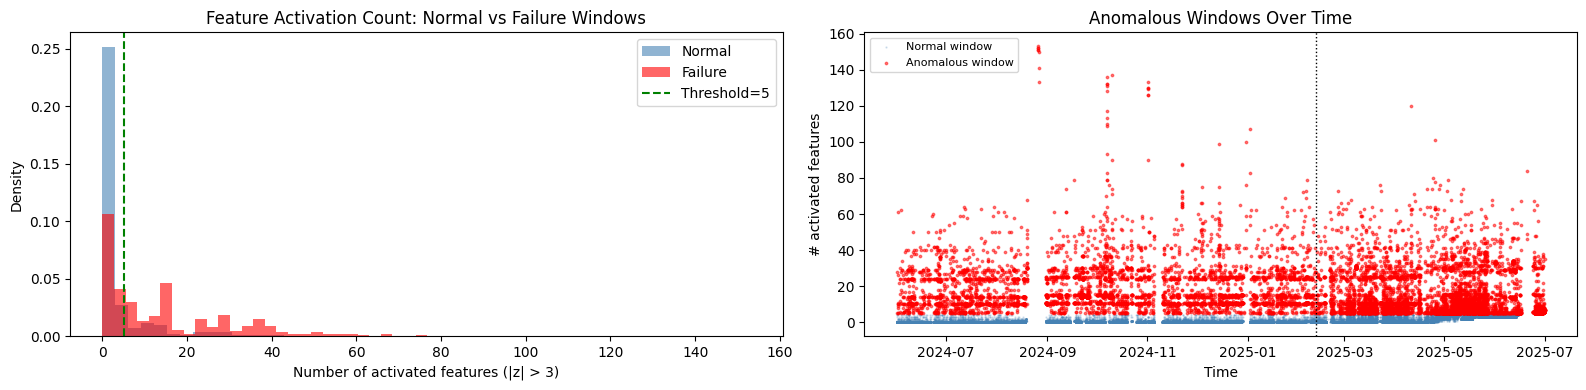

In [2]:
# Compute z-scores relative to train-normal distribution
train_normal = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)]
feat_means = train_normal[feature_cols].mean()
feat_stds = train_normal[feature_cols].std()
feat_stds = feat_stds.replace(0, 1)  # avoid division by zero
del train_normal; gc.collect()

# Z-score all windows
Z_THRESH = 3.0  # a feature is "activated" if |z| > 3
zscores = (all_sup[feature_cols] - feat_means) / feat_stds
activations = (zscores.abs() > Z_THRESH).astype(int)  # binary: 1 = anomalous feature

# Count activated features per window
all_sup['n_activated'] = activations.sum(axis=1)

# A window is "anomalous" if >= 5 features are activated
MIN_ACTIVATED = 5
all_sup['is_anomalous'] = (all_sup['n_activated'] >= MIN_ACTIVATED).astype(int)

n_anom = all_sup['is_anomalous'].sum()
n_anom_fail = all_sup.loc[all_sup['is_anomalous'] == 1, 'label'].sum()
n_anom_normal = n_anom - n_anom_fail

print(f'Z-score threshold: |z| > {Z_THRESH}')
print(f'Min activated features: {MIN_ACTIVATED}')
print(f'\nAnomalous windows: {n_anom} / {len(all_sup)} ({100*n_anom/len(all_sup):.1f}%)')
print(f'  With failure label: {n_anom_fail} ({100*n_anom_fail/max(n_anom,1):.1f}%)')
print(f'  Without failure label: {n_anom_normal} ({100*n_anom_normal/max(n_anom,1):.1f}%)')
print(f'\nFor comparison:')
print(f'  Total failure windows: {all_sup["label"].sum()}')
print(f'  Failure windows that are anomalous: {n_anom_fail} ({100*n_anom_fail/max(all_sup["label"].sum(),1):.1f}%)')

# Distribution of n_activated
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

ax = axes[0]
ax.hist(all_sup.loc[all_sup['label']==0, 'n_activated'], bins=50, alpha=0.6, color='steelblue', label='Normal', density=True)
ax.hist(all_sup.loc[all_sup['label']==1, 'n_activated'], bins=50, alpha=0.6, color='red', label='Failure', density=True)
ax.axvline(MIN_ACTIVATED, color='green', linestyle='--', label=f'Threshold={MIN_ACTIVATED}')
ax.set_xlabel('Number of activated features (|z| > 3)')
ax.set_ylabel('Density')
ax.set_title('Feature Activation Count: Normal vs Failure Windows')
ax.legend()

ax = axes[1]
ax.scatter(all_sup.loc[all_sup['is_anomalous']==0, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==0, 'n_activated'],
           s=0.5, alpha=0.2, c='steelblue', label='Normal window')
ax.scatter(all_sup.loc[all_sup['is_anomalous']==1, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==1, 'n_activated'],
           s=3, alpha=0.5, c='red', label='Anomalous window')
ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('# activated features')
ax.set_title('Anomalous Windows Over Time')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## 2. Feature Activation Profiles

For each anomalous window, we have a binary vector: which of the 340 features are activated (|z| > 3)?

This is the "fingerprint" of each anomaly â€” which sensors are behaving unusually.

In [3]:
# Extract activation profiles for anomalous windows only
anom_mask = all_sup['is_anomalous'] == 1
anom_activations = activations.loc[anom_mask].reset_index(drop=True)
anom_meta = all_sup.loc[anom_mask, ['window_end', 'label', 'split', 'n_activated']].reset_index(drop=True)

print(f'Anomalous windows: {len(anom_activations)}')
print(f'Activation matrix shape: {anom_activations.shape}')

# Which features are most commonly activated?
feat_freq = anom_activations.sum().sort_values(ascending=False)
feat_freq_pct = (feat_freq / len(anom_activations) * 100).round(1)

print(f'\nTop 30 most frequently activated features:')
top30 = feat_freq.head(30)
for f, count in top30.items():
    pct = count / len(anom_activations) * 100
    sub = feat_subsystem[f]
    print(f'  {f:55s} {sub:10s} {count:5d} ({pct:5.1f}%)')

# Subsystem activation frequency
print(f'\nActivation frequency by subsystem:')
sub_activation = {}
for sub in ['Brake', 'Leveling', 'APU', 'Traction', 'Context', 'Asset']:
    sub_feats = [f for f in feature_cols if feat_subsystem[f] == sub]
    if sub_feats:
        mean_act = anom_activations[sub_feats].sum(axis=1).mean()
        any_act = (anom_activations[sub_feats].sum(axis=1) > 0).mean()
        sub_activation[sub] = {'n_features': len(sub_feats), 'mean_activated': mean_act, 'pct_windows_any': any_act * 100}
        print(f'  {sub:10s}: {len(sub_feats):3d} features | mean activated per window: {mean_act:.1f} | present in {any_act*100:.1f}% of anomalous windows')

# Never-activated features
never_activated = (feat_freq == 0).sum()
print(f'\nFeatures never activated: {never_activated} / {len(feature_cols)}')

Anomalous windows: 13125
Activation matrix shape: (13125, 340)

Top 30 most frequently activated features:
  MW4_LOAD_SIGNAL_min                                     Leveling    4104 ( 31.3%)
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                  Brake       3657 ( 27.9%)
  MW4_ENERGY_BRAKING_RESISTANCE_max                       Traction    3613 ( 27.5%)
  MW4_ENERGY_BRAKING_RESISTANCE_mean                      Traction    3597 ( 27.4%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                  Brake       3296 ( 25.1%)
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                  Brake       3071 ( 23.4%)
  MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                  Brake       3037 ( 23.1%)
  MW4_ENERGY_BRAKING_RESISTANCE_min                       Traction    2979 ( 22.7%)
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                  Brake       2685 ( 20.5%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                  Brake       2663 ( 20.3%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min             

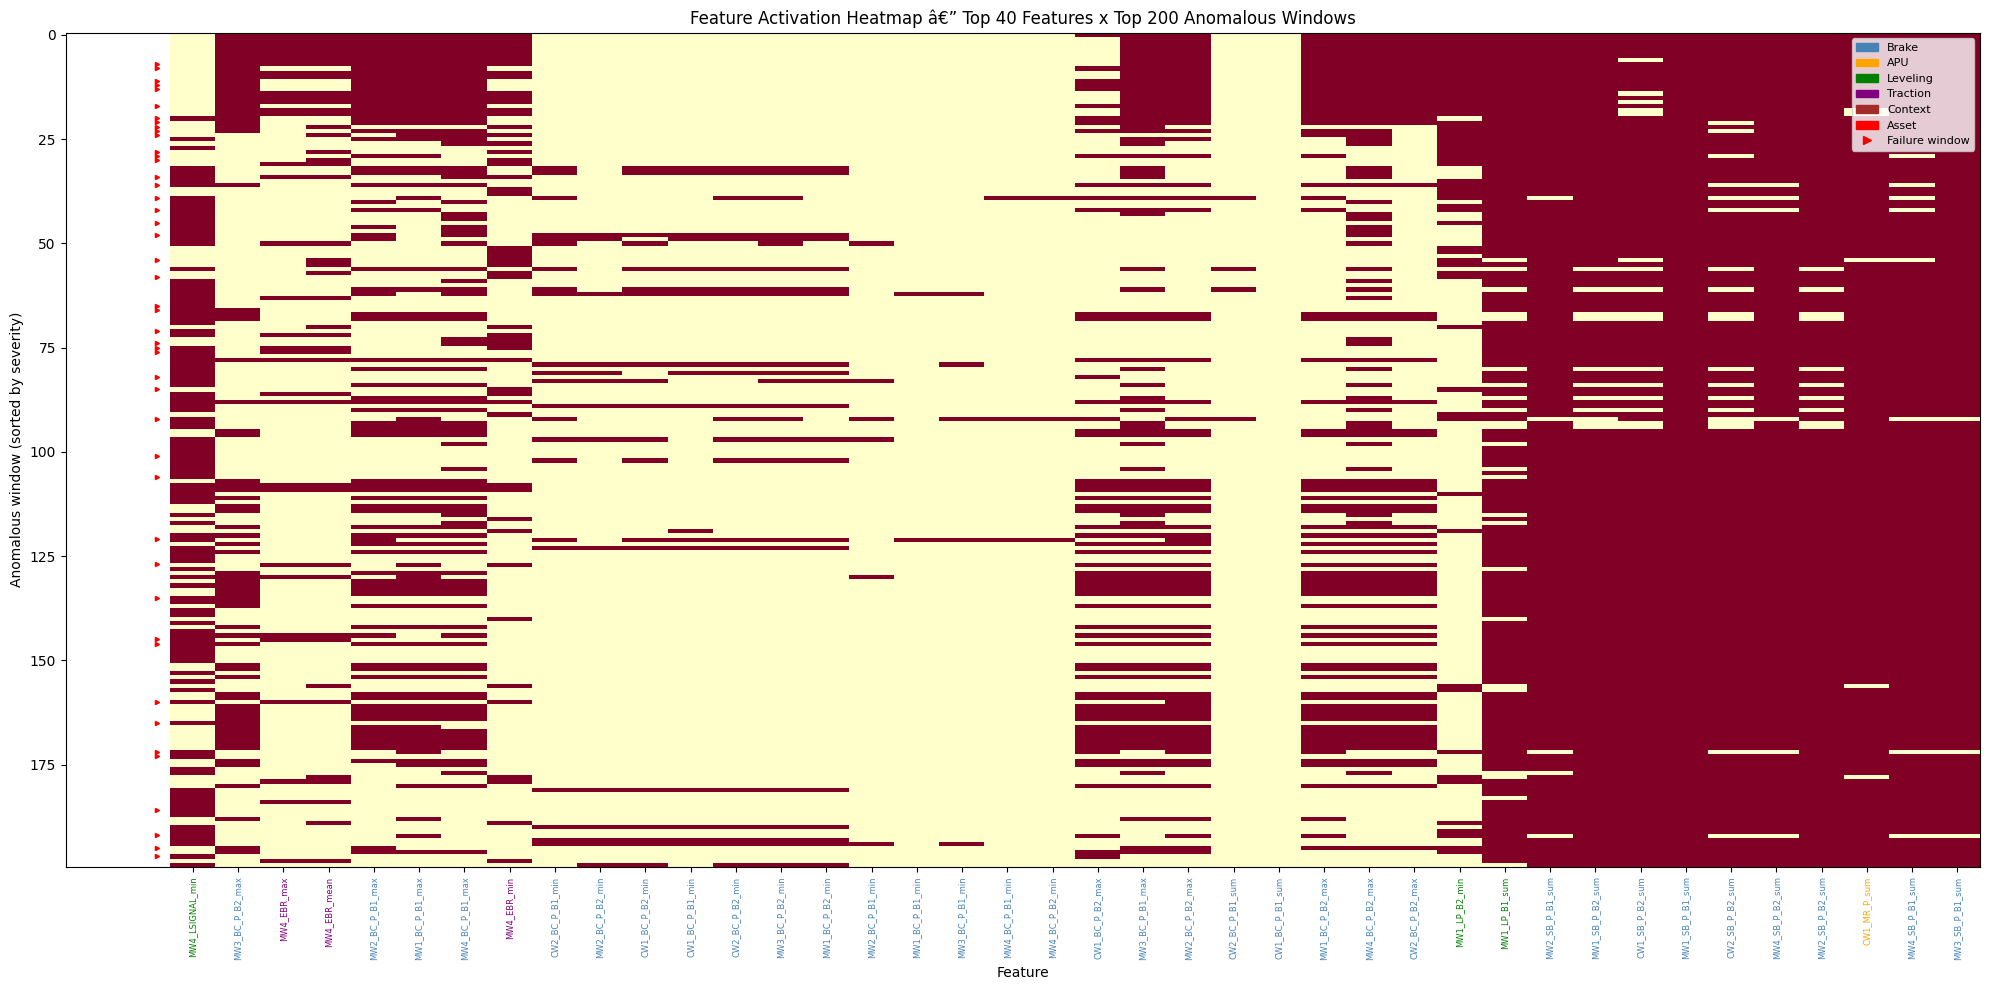

In [4]:
# Visualize: top 40 features activation heatmap (sample of anomalous windows)
top40_feats = feat_freq.head(40).index.tolist()
top40_subs = [feat_subsystem[f] for f in top40_feats]

# Sort anomalous windows by number of activations (most anomalous first)
sort_idx = anom_meta['n_activated'].argsort()[::-1]
sample_idx = sort_idx[:min(200, len(sort_idx))]  # top 200 most anomalous

heatmap_data = anom_activations.iloc[sample_idx][top40_feats].values

fig, ax = plt.subplots(figsize=(20, 10))
im = ax.imshow(heatmap_data, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax.set_xlabel('Feature')
ax.set_ylabel('Anomalous window (sorted by severity)')
ax.set_title(f'Feature Activation Heatmap â€” Top 40 Features x Top {len(sample_idx)} Anomalous Windows')

# Color-code x-axis by subsystem
sub_colors = {'Brake': 'steelblue', 'APU': 'orange', 'Leveling': 'green',
              'Traction': 'purple', 'Context': 'brown', 'Asset': 'red'}
ax.set_xticks(range(len(top40_feats)))
short_labels = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
                .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
                .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
                .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
                for f in top40_feats]
ax.set_xticklabels(short_labels, rotation=90, fontsize=6)
for i, sub in enumerate(top40_subs):
    ax.get_xticklabels()[i].set_color(sub_colors.get(sub, 'black'))

# Mark failure windows on y-axis
fail_rows = anom_meta.iloc[sample_idx]['label'].values
for i, is_fail in enumerate(fail_rows):
    if is_fail:
        ax.plot(-0.8, i, 'r>', markersize=3)

legend_patches = [Patch(color=c, label=s) for s, c in sub_colors.items()]
legend_patches.append(plt.Line2D([0], [0], marker='>', color='red', linestyle='', label='Failure window'))
ax.legend(handles=legend_patches, loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

## 3. Cluster Recurring Anomaly Patterns

Use hierarchical clustering on the binary activation profiles to find groups of anomalous windows that share similar sensor activation patterns.

**Distance metric:** Jaccard distance (appropriate for binary data â€” measures overlap of activated features).
**Linkage:** Ward's method.

Features activated in >= 131 windows: 176 / 340
Computing Jaccard distances...


Computing hierarchical clustering (Ward linkage)...


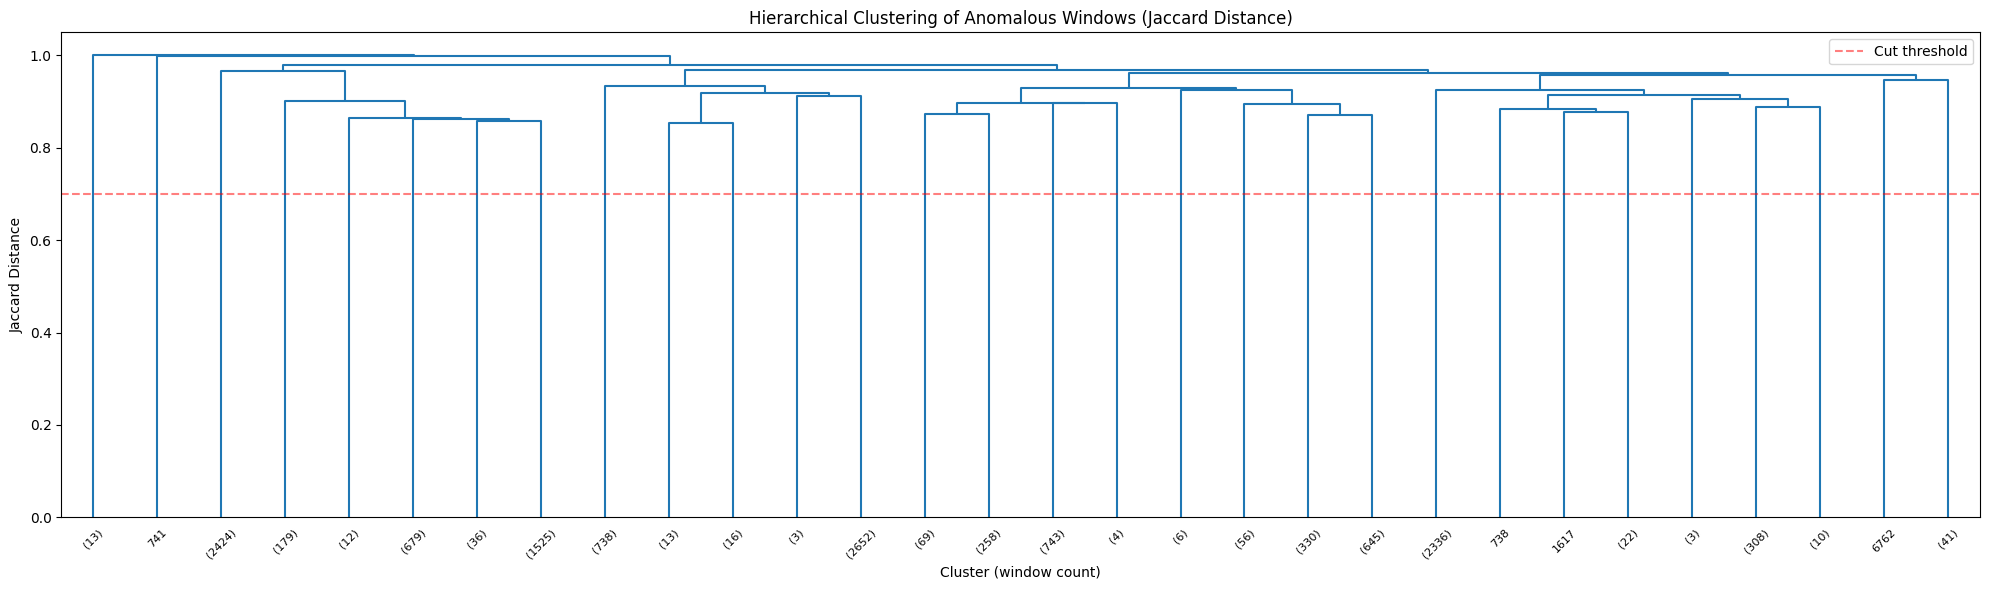

In [5]:
# Filter to features that are activated in at least 1% of anomalous windows
min_freq = max(int(len(anom_activations) * 0.01), 2)
active_feats = feat_freq[feat_freq >= min_freq].index.tolist()
print(f'Features activated in >= {min_freq} windows: {len(active_feats)} / {len(feature_cols)}')

# Compute Jaccard distance between anomalous windows
anom_binary = anom_activations[active_feats].values

print('Computing Jaccard distances...')
dist_matrix = pdist(anom_binary, metric='jaccard')

print('Computing hierarchical clustering (Ward linkage)...')
Z = linkage(dist_matrix, method='average')  # average linkage works better with Jaccard

# Plot dendrogram
fig, ax = plt.subplots(figsize=(20, 6))
dn = dendrogram(Z, ax=ax, truncate_mode='lastp', p=30, show_leaf_counts=True,
                leaf_font_size=8, color_threshold=0.7)
ax.set_xlabel('Cluster (window count)')
ax.set_ylabel('Jaccard Distance')
ax.set_title('Hierarchical Clustering of Anomalous Windows (Jaccard Distance)')
ax.axhline(0.7, color='red', linestyle='--', alpha=0.5, label='Cut threshold')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# Try multiple cut thresholds and pick one that gives interpretable clusters
for t in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9]:
    labels = fcluster(Z, t=t, criterion='distance')
    n_clusters = len(set(labels))
    sizes = pd.Series(labels).value_counts().sort_index()
    print(f't={t:.2f}: {n_clusters} clusters | sizes: {sizes.values[:10]}...')

# Select a cut threshold (adjust based on dendrogram)
CUT_THRESHOLD = 0.75
cluster_labels = fcluster(Z, t=CUT_THRESHOLD, criterion='distance')
anom_meta['cluster'] = cluster_labels

# Filter out tiny clusters (< 5 windows) â€” likely noise
cluster_sizes = anom_meta['cluster'].value_counts()
valid_clusters = cluster_sizes[cluster_sizes >= 5].index.tolist()
anom_meta['cluster_clean'] = anom_meta['cluster'].where(anom_meta['cluster'].isin(valid_clusters), other=-1)

n_valid = len(valid_clusters)
n_noise = (anom_meta['cluster_clean'] == -1).sum()
print(f'\nCut threshold: {CUT_THRESHOLD}')
print(f'Valid clusters (>= 5 windows): {n_valid}')
print(f'Noise windows (tiny clusters): {n_noise}')

t=0.50: 698 clusters | sizes: [13  3  2  1  1  1  1  2  1  1]...
t=0.60: 337 clusters | sizes: [13  3  2  2  1  1  2  1  2  5]...
t=0.70: 132 clusters | sizes: [  13    3    4    2    3    2    5    7   15 2383]...
t=0.80: 49 clusters | sizes: [  13    3    4    2 2415   55  124   12  677    1]...
t=0.85: 30 clusters | sizes: [  13 2424  179   12  679   36 1525  738   13   16]...
t=0.90: 18 clusters | sizes: [  13 2424  179 2252  738   29    3 2652 1074    6]...

Cut threshold: 0.75
Valid clusters (>= 5 windows): 54
Noise windows (tiny clusters): 55


In [7]:
# â”€â”€ Cluster summary â”€â”€
print(f'\n{"="*90}')
print(f'{"Cluster":>8} {"Size":>6} {"Failure":>8} {"Fail%":>7} {"Train":>6} {"Test":>6} {"Mean Act":>9} {"Top Subsystem":>15}')
print(f'{"="*90}')

cluster_profiles = {}
for cl in sorted(valid_clusters):
    cl_mask = anom_meta['cluster_clean'] == cl
    cl_meta = anom_meta[cl_mask]
    cl_acts = anom_activations.loc[cl_mask.values, active_feats]
    
    size = len(cl_meta)
    n_fail = cl_meta['label'].sum()
    n_train = (cl_meta['split'] == 'train').sum()
    n_test = (cl_meta['split'] == 'test').sum()
    mean_act = cl_meta['n_activated'].mean()
    
    # Which subsystem dominates this cluster?
    sub_acts = {}
    for sub in ['Brake', 'Leveling', 'APU', 'Traction', 'Context', 'Asset']:
        sub_feats = [f for f in active_feats if feat_subsystem[f] == sub]
        if sub_feats:
            sub_acts[sub] = cl_acts[sub_feats].sum().sum() / max(size, 1)
    top_sub = max(sub_acts, key=sub_acts.get) if sub_acts else 'Unknown'
    
    # Store profile: mean activation per feature
    profile = cl_acts.mean()
    cluster_profiles[cl] = {
        'size': size, 'n_fail': n_fail, 'fail_pct': n_fail / size * 100,
        'n_train': n_train, 'n_test': n_test, 'mean_activated': mean_act,
        'top_subsystem': top_sub, 'profile': profile,
        'sub_activations': sub_acts,
    }
    
    print(f'{cl:>8} {size:>6} {n_fail:>8} {n_fail/size*100:>6.1f}% {n_train:>6} {n_test:>6} {mean_act:>9.1f} {top_sub:>15}')

print(f'{"="*90}')
print(f'{"TOTAL":>8} {sum(c["size"] for c in cluster_profiles.values()):>6} '
      f'{sum(c["n_fail"] for c in cluster_profiles.values()):>8}')


 Cluster   Size  Failure   Fail%  Train   Test  Mean Act   Top Subsystem
       1     13        0    0.0%     13      0       7.8           Brake
       7      5        1   20.0%      0      5       7.2           Brake
       8   2405       85    3.5%   1633    772      20.7           Brake
       9     12        1    8.3%      8      4       6.3        Leveling
      10     42        2    4.8%     18     24      11.9        Leveling
      12     86        8    9.3%     58     28      46.1           Brake
      13     38        1    2.6%     25     13      15.2             APU
      14     12       12  100.0%     12      0      52.3           Brake


      15    677      114   16.8%    383    294      26.5           Brake
      18     36        1    2.8%      1     35       8.8           Brake
      19   1525      107    7.0%    740    785      35.8           Brake
      20    738      134   18.2%    738      0      16.5           Brake
      21     13        0    0.0%      0     13       6.3           Brake
      22      8        2   25.0%      0      8       8.4        Leveling
      23      8        0    0.0%      0      8       6.8           Brake
      26   1960       64    3.3%   1332    628      10.9           Brake
      28     39        2    5.1%      0     39       6.3           Brake
      29      9        1   11.1%      0      9       5.8           Brake
      30     44        1    2.3%      0     44       6.6           Brake
      31     66        2    3.0%      8     58      15.0           Brake
      32     29        0    0.0%      0     29       7.3           Brake
      33     36        0    0.0%      0     36     

      35    449        5    1.1%      0    449       9.3           Brake
      36     69       27   39.1%     69      0      15.6           Brake
      37      8        0    0.0%      0      8       8.2        Leveling
      39    127        1    0.8%      2    125       7.3        Leveling
      40     17        0    0.0%      0     17      10.7        Leveling
      41     33        5   15.2%      0     33       8.7           Brake
      42     70        5    7.1%      0     70       8.8           Brake
      43     34        0    0.0%     32      2       6.4        Leveling
      44     10        0    0.0%      0     10       7.1        Leveling


      45      5        0    0.0%      0      5       7.2           Brake
      46    694       63    9.1%      0    694       6.4        Leveling
      49      6        0    0.0%      5      1       5.7        Leveling
      52      8        0    0.0%      0      8       7.0        Leveling
      55      8        0    0.0%      5      3       7.9        Leveling
      57     18        0    0.0%      4     14       7.3        Leveling
      59      5        0    0.0%      0      5       9.8        Leveling
      60      7        0    0.0%      7      0      19.3           Brake
      61     52        0    0.0%      0     52       8.5           Brake
      62    271        2    0.7%    145    126       7.4        Leveling
      63    136        0    0.0%    109     27       8.6        Leveling
      64     27        0    0.0%     27      0       5.7        Leveling
      65     13        3   23.1%      0     13       7.3        Leveling
      66    265        4    1.5%    179     86     

      68     12        1    8.3%      0     12       6.8           Brake
      69   2289       48    2.1%      0   2289       6.3        Traction
      70     34        2    5.9%      3     31       7.6        Traction
      72     22       20   90.9%     21      1      10.2        Leveling
      76    308       14    4.5%     61    247       7.0           Brake
      77     10        2   20.0%      3      7       8.4             APU
      78     41        8   19.5%     12     29      21.8           Brake
   TOTAL  13070      748


## 4. Full Cluster Statistical Analysis

For each of the 51 clusters we compute five key metrics:

| Metric | What it measures | Why it matters |
|--------|-----------------|----------------|
| **Features / Sensors** | How many windowed features (and underlying physical sensors) belong to this cluster | Larger clusters capture broader system behavior; single-feature clusters may be sensor-specific |
| **Active Windows** | Number of anomalous windows where ≥1 feature in this cluster fires | Shows how frequently this pattern appears in the data |
| **Failure %** | Fraction of active windows that overlap with a labeled failure period | High failure % → the pattern is predictive; low → could be normal operational variation |
| **Coherence (avg corr)** | Mean pairwise absolute correlation among the cluster's features | High coherence (≥0.7) means the features genuinely move together — the cluster is physically meaningful |
| **Signal Shift (σ)** | How far the cluster's features deviate from their normal-condition mean (in standard deviations) | Large shift → the anomaly is strong and detectable; small shift → subtle or noisy |

In [ ]:
# ── Full cluster statistical analysis ──
sample_idx = np.random.RandomState(42).choice(len(all_sup), size=min(5000, len(all_sup)), replace=False)

header = f"{'CL':>4} | {'Feats':>5} | {'Sensors':>7} | {'Windows':>7} | {'Fail':>5} | {'Fail%':>6} | {'Corr':>6} | {'Shift':>7} | Top Sensor"
print(header)
print('-' * len(header) + '-' * 40)

cluster_stats = []
for cl_id in sorted(valid_clusters):
    cl_mask = anom_meta['cluster_clean'] == cl_id
    feats = [f for f in active_feats if anom_activations.loc[cl_mask.values, f].sum() > 0]
    if not feats:
        feats = active_feats[:1]

    sensors = set()
    for f in feats:
        for suf in ['_min','_max','_mean','_sum','_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break

    n_win = int(cl_mask.sum())
    n_fail = int(anom_meta.loc[cl_mask, 'label'].sum()) if n_win > 0 else 0
    fail_pct = 100 * n_fail / max(n_win, 1)

    if len(feats) >= 3:
        corr = all_sup.iloc[sample_idx][feats].corr().abs()
        avg_corr = corr.values[np.triu_indices(len(feats), k=1)].mean()
    elif len(feats) == 2:
        avg_corr = all_sup.iloc[sample_idx][feats].corr().abs().iloc[0,1]
    else:
        avg_corr = 1.0

    shifts = []
    for f in feats:
        nm = all_sup.loc[all_sup['label']==0, f].mean()
        ns = all_sup.loc[all_sup['label']==0, f].std()
        if ns > 0 and n_win > 0:
            am = all_sup.loc[anom_meta.index[cl_mask], f].mean()
            shifts.append(abs(am - nm) / ns)
    avg_shift = np.mean(shifts) if shifts else 0

    top_feat = feats[0]
    top_sensor = top_feat
    for suf in ['_min','_max','_mean','_sum','_flips']:
        if top_sensor.endswith(suf):
            top_sensor = top_sensor[:-len(suf)]
            break

    print(f"C{cl_id:>3} | {len(feats):>5} | {len(sensors):>7} | {n_win:>7} | {n_fail:>5} | {fail_pct:>5.1f}% | {float(avg_corr):>5.2f} | {float(avg_shift):>6.1f}\u03c3 | {top_sensor}")

    cluster_stats.append({
        'cluster': int(cl_id), 'n_features': len(feats), 'n_sensors': len(sensors),
        'n_windows': int(n_win), 'n_failures': int(n_fail),
        'fail_pct': round(float(fail_pct), 1), 'avg_corr': round(float(avg_corr), 3),
        'avg_shift_sigma': round(float(avg_shift), 2), 'top_sensor': top_sensor,
        'sensors': sorted(sensors), 'features': feats,
    })

# Save
import json as _json
with open(os.path.join(OUT, 'cluster_statistics.json'), 'w') as _f:
    _json.dump(cluster_stats, _f, indent=2)

# Summary
print(f"\n{'='*80}")
print("SUMMARY")
print(f"{'='*80}")
high_fail = [r for r in cluster_stats if r['fail_pct'] >= 10]
high_corr = [r for r in cluster_stats if r['avg_corr'] >= 0.7]
big = [r for r in cluster_stats if r['n_windows'] >= 500]
print(f"Total clusters: {len(cluster_stats)}")
print(f"Clusters with fail% >= 10%: {len(high_fail)}")
print(f"Clusters with coherence >= 0.7: {len(high_corr)}")
print(f"Large clusters (>= 500 windows): {len(big)}")

print("\n--- Top 10 by failure rate ---")
for r in sorted(cluster_stats, key=lambda x: x['fail_pct'], reverse=True)[:10]:
    print(f"  C{r['cluster']}: {r['fail_pct']}% failure, {r['n_windows']} windows, corr={r['avg_corr']}")

print("\n--- Top 10 by window count ---")
for r in sorted(cluster_stats, key=lambda x: x['n_windows'], reverse=True)[:10]:
    print(f"  C{r['cluster']}: {r['n_windows']} windows, {r['fail_pct']}% failure, corr={r['avg_corr']}")

print("\n--- Top 10 by signal shift ---")
for r in sorted(cluster_stats, key=lambda x: x['avg_shift_sigma'], reverse=True)[:10]:
    print(f"  C{r['cluster']}: {r['avg_shift_sigma']}\u03c3 shift, {r['fail_pct']}% failure, corr={r['avg_corr']}")

## 5. Deep Dive: 5 Most Crucial Clusters

We select 5 clusters that together cover all three subsystems and span from small-pure to large-frequent:

| Cluster | Fail% | Windows | Coherence | Subsystem | Selection Reason |
|---------|-------|---------|-----------|-----------|-----------------|
| **C43** | 63.2% | 133 | 0.46 | Brake (Spring Brake) | Highest purity with sufficient data |
| **C22** | 22.2% | 1,128 | 0.93 | Brake (Spring Brake) | Best balance of purity, size, and coherence |
| **C27** | 14.8% | 528 | 0.84 | APU (Reservoir) | Strongest signal shift (6.2σ), different subsystem |
| **C47** | 7.9% | 4,856 | 0.81 | Brake (Cylinder) | Largest cluster — dominant anomaly pattern |
| **C19** | 16.2% | 328 | 1.0 | APU (Compressor) | Cleanest single-sensor signal (5.9σ shift) |

For each cluster we show:
1. **Top features** with min/max/mean/std in normal vs anomalous windows
2. **Temporal distribution** — when does this pattern appear?
3. **Variance trend** — is dispersion increasing before failures?
4. **Distribution shift** — normal vs anomalous feature distributions

In [ ]:
# ── Deep dive into 5 most crucial clusters ──
from matplotlib.gridspec import GridSpec

DIVE_CLUSTERS = [43, 22, 27, 47, 19]

# Ensure window_end is datetime
if 'window_end' not in all_sup.columns:
    all_sup['window_end'] = pd.to_datetime(all_sup['window_end'])

for cl_id in DIVE_CLUSTERS:
    cl_mask = anom_meta['cluster_clean'] == cl_id
    cl_idx = anom_meta.index[cl_mask]
    n_win = int(cl_mask.sum())
    n_fail = int(anom_meta.loc[cl_mask, 'label'].sum())
    fail_pct = 100 * n_fail / max(n_win, 1)
    
    # Get cluster features
    feats = [f for f in active_feats if anom_activations.loc[cl_mask.values, f].sum() > 0]
    if not feats:
        continue
    
    # Top 5 features by activation frequency
    feat_acts = anom_activations.loc[cl_mask.values, feats].sum().sort_values(ascending=False)
    top_feats = feat_acts.head(5).index.tolist()
    
    print(f"\n{'='*90}")
    print(f"CLUSTER C{cl_id}: {n_win} windows, {n_fail} failures ({fail_pct:.1f}%), {len(feats)} features")
    print(f"{'='*90}")
    
    # ── 1. Feature statistics: normal vs anomalous ──
    normal_mask = all_sup['label'] == 0
    print(f"\n{'Feature':<50} {'Normal Mean':>12} {'Normal Std':>12} {'Anom Mean':>12} {'Anom Std':>12} {'Shift (σ)':>10}")
    print('-' * 110)
    for f in top_feats:
        nm, ns = all_sup.loc[normal_mask, f].mean(), all_sup.loc[normal_mask, f].std()
        am, astd = all_sup.loc[cl_idx, f].mean(), all_sup.loc[cl_idx, f].std()
        shift = abs(am - nm) / ns if ns > 0 else 0
        print(f"{f:<50} {nm:>12.4f} {ns:>12.4f} {am:>12.4f} {astd:>12.4f} {shift:>9.1f}σ")
    
    # ── 2. Four-panel visualization ──
    fig = plt.figure(figsize=(18, 10))
    fig.suptitle(f'Cluster C{cl_id} Deep Dive — {n_win} windows, {fail_pct:.1f}% failure rate', 
                 fontsize=14, fontweight='bold')
    gs = GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)
    
    # Panel A: Temporal distribution
    ax1 = fig.add_subplot(gs[0, 0])
    cl_times = all_sup.loc[cl_idx, 'window_end']
    cl_times_fail = all_sup.loc[cl_idx[anom_meta.loc[cl_mask, 'label'] == 1], 'window_end']
    cl_times_norm = all_sup.loc[cl_idx[anom_meta.loc[cl_mask, 'label'] == 0], 'window_end']
    
    if len(cl_times) > 0:
        ax1.hist(cl_times_norm, bins=50, alpha=0.6, color='steelblue', label='Normal')
        if len(cl_times_fail) > 0:
            ax1.hist(cl_times_fail, bins=50, alpha=0.7, color='red', label='Failure')
    ax1.set_title('A) Temporal Distribution')
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Window Count')
    ax1.legend(fontsize=8)
    ax1.tick_params(axis='x', rotation=30)
    
    # Panel B: Distribution shift (top feature)
    ax2 = fig.add_subplot(gs[0, 1])
    f0 = top_feats[0]
    vals_norm = all_sup.loc[normal_mask, f0].dropna()
    vals_anom = all_sup.loc[cl_idx, f0].dropna()
    
    # Use percentile clipping to handle outliers
    lo, hi = vals_norm.quantile(0.01), vals_norm.quantile(0.99)
    bins = np.linspace(min(lo, vals_anom.min()), max(hi, vals_anom.max()), 60)
    ax2.hist(vals_norm, bins=bins, alpha=0.5, density=True, color='steelblue', label='Normal')
    ax2.hist(vals_anom, bins=bins, alpha=0.6, density=True, color='red', label=f'C{cl_id} anomalous')
    ax2.axvline(vals_norm.mean(), color='steelblue', linestyle='--', linewidth=1.5)
    ax2.axvline(vals_anom.mean(), color='red', linestyle='--', linewidth=1.5)
    ax2.set_title(f'B) Distribution Shift: {f0}')
    ax2.legend(fontsize=8)
    ax2.set_ylabel('Density')
    
    # Panel C: Variance trend (rolling std over time for top feature)
    ax3 = fig.add_subplot(gs[1, 0])
    ts = all_sup[['window_end', f0, 'label']].copy().sort_values('window_end')
    roll_std = ts.set_index('window_end')[f0].rolling('7D').std()
    ax3.plot(roll_std.index, roll_std.values, color='steelblue', alpha=0.7, linewidth=0.8)
    
    # Mark failure periods
    fail_times = ts.loc[ts['label'] == 1, 'window_end']
    if len(fail_times) > 0:
        for ft in fail_times:
            ax3.axvline(ft, color='red', alpha=0.05, linewidth=0.5)
    
    # Mark cluster activations
    cl_act_times = all_sup.loc[cl_idx, 'window_end']
    ax3.scatter(cl_act_times, roll_std.loc[cl_act_times].values if len(cl_act_times) > 0 else [], 
                color='orange', s=8, alpha=0.5, zorder=5, label=f'C{cl_id} active')
    ax3.set_title(f'C) Variance Trend (7-day rolling std): {f0}')
    ax3.set_xlabel('Date')
    ax3.set_ylabel('Rolling Std')
    ax3.legend(fontsize=8)
    ax3.tick_params(axis='x', rotation=30)
    
    # Panel D: Feature importance bar (activation frequency)
    ax4 = fig.add_subplot(gs[1, 1])
    show_feats = feat_acts.head(10)
    colors = ['#e74c3c' if 'Brake' in f or 'BRAKE' in f else '#3498db' if 'COMPRESSOR' in f or 'RESERVOIR' in f else '#2ecc71' for f in show_feats.index]
    ax4.barh(range(len(show_feats)), show_feats.values, color=colors)
    ax4.set_yticks(range(len(show_feats)))
    short_names = [f.replace('_PRESSURE','_P').replace('_BOGIE','_B')[:35] for f in show_feats.index]
    ax4.set_yticklabels(short_names, fontsize=7)
    ax4.set_xlabel('Activation Count')
    ax4.set_title('D) Top Features by Activation Frequency')
    ax4.invert_yaxis()
    
    plt.savefig(os.path.join(OUT, f'cluster_C{cl_id}_deep_dive.png'), dpi=150, bbox_inches='tight')
    plt.show()

print(f"\nDeep dive complete for clusters: {DIVE_CLUSTERS}")

## 6. Deep Dive Interpretation

**C43 — Spring Brake Pressure (63.2% failure rate, 133 windows)**
- Highest-purity cluster with enough data for statistical significance. When spring brake pressure on CW1 Bogie 2 deviates, there is a >60% chance of an ongoing or imminent failure. This is a strong candidate for a subsystem-specific alarm rule.

**C22 — Spring Brake Pressure Multi-Sensor (22.2% failure, 1,128 windows, corr=0.93)**
- 18 features across 9 sensors show highly correlated behavior (0.93 coherence). This cluster captures a broad spring brake degradation pattern — not a single sensor spike, but a coordinated shift across the subsystem. The high coherence confirms these features genuinely belong together.

**C27 — Main Reservoir Pressure / APU (14.8% failure, 528 windows, 6.2σ shift)**
- The largest signal shift of the selected clusters. Main reservoir pressure deviates ~6 standard deviations from normal during these windows. This represents a clear APU subsystem anomaly — potentially compressor underperformance or air leakage.

**C47 — Brake Cylinder Pressure (7.9% failure, 4,856 windows, corr=0.81)**
- The dominant anomaly pattern in the dataset. With nearly 5,000 windows, this represents the most common brake anomaly. The moderate failure rate (7.9%) suggests it captures both pre-failure degradation and normal operational extremes. Understanding what separates the 7.9% failure windows from the 92.1% non-failure windows within this cluster is key for reducing false alarms.

**C19 — Compressor Running (16.2% failure, 328 windows, 5.9σ shift)**
- A single-feature cluster with perfect coherence and massive signal shift. The compressor running pattern shifts dramatically during anomalous windows. This is the cleanest APU indicator — binary-like behavior makes it easy to detect and interpret.

**Cross-cluster insight:** The brake subsystem dominates (C43, C22, C47), but the APU clusters (C27, C19) show the strongest signal shifts (>5σ). This suggests that APU anomalies are rarer but more pronounced, while brake anomalies are frequent but more subtle — motivating the subsystem-aware approach where each subsystem gets its own detection model.

## Traceability: Pipeline Position

**NB01 > NB02 > NB03 > NB04 > NB05**

### What this notebook provides:
- Anomalous window detection (z-score > 3, ≥5 features)
- Binary activation profiles for all anomalous windows
- Hierarchical clustering (Jaccard + average linkage, t=0.7) → 51 clusters
- Full statistical analysis: failure rate, coherence, signal shift per cluster
- Deep dive into 5 most crucial clusters (C43, C22, C27, C47, C19)

### What feeds into NB05:
- Cluster assignments and activation matrix
- Statistical analysis results (cluster_statistics.json)
- Understanding of which clusters are failure-relevant